In [74]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [75]:
from datasets import load_dataset

ds = load_dataset("sh0416/ag_news")

In [76]:
train_data = ds["train"]
test_data = ds["test"]

In [77]:
print(train_data)
print(test_data)

Dataset({
    features: ['label', 'title', 'description'],
    num_rows: 120000
})
Dataset({
    features: ['label', 'title', 'description'],
    num_rows: 7600
})


In [78]:
print(train_data[0])
print(train_data.features)

{'label': 3, 'title': 'Wall St. Bears Claw Back Into the Black (Reuters)', 'description': "Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again."}
{'label': Value('int64'), 'title': Value('string'), 'description': Value('string')}


In [79]:
train_df = train_data.to_pandas()
test_df = test_data.to_pandas()

In [80]:
print("Training Shape:", train_df.shape)
print("Testing Shape:", test_df.shape)

Training Shape: (120000, 3)
Testing Shape: (7600, 3)


In [81]:
train_df.head()

,label,title,description
0,3,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindli..."
1,3,Carlyle Looks Toward Commercial Aerospace (Reu...,Reuters - Private investment firm Carlyle Grou...
2,3,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\ab...
3,3,Iraq Halts Oil Exports from Main Southern Pipe...,Reuters - Authorities have halted oil export\f...
4,3,"Oil prices soar to all-time record, posing new...","AFP - Tearaway world oil prices, toppling reco..."


In [82]:
print(train_df.columns)

Index(['label', 'title', 'description'], dtype='str')


In [83]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 3 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   label        120000 non-null  int64
 1   title        120000 non-null  str  
 2   description  120000 non-null  str  
dtypes: int64(1), str(2)
memory usage: 2.7 MB


In [84]:
train_df.describe(include="all")

,label,title,description
count,120000.000000,120000,120000
unique,NaN,114364,118731
top,NaN,Today's schedule,"With the economy slowly turning up, upgrading ..."
freq,NaN,39,15
mean,2.500000,NaN,NaN
std,1.118039,NaN,NaN
min,1.000000,NaN,NaN
25%,1.750000,NaN,NaN
50%,2.500000,NaN,NaN
75%,3.250000,NaN,NaN


In [85]:
label_mapping = {
    1: "World",
    2: "Sports",
    3: "Business",
    4: "Sci/Tech"
}

train_df["category"] = train_df["label"].map(label_mapping)
test_df["category"] = test_df["label"].map(label_mapping)

print(train_df[["title", "category"]].head(10))

                                               title  category
0  Wall St. Bears Claw Back Into the Black (Reuters)  Business
1  Carlyle Looks Toward Commercial Aerospace (Reu...  Business
2    Oil and Economy Cloud Stocks' Outlook (Reuters)  Business
3  Iraq Halts Oil Exports from Main Southern Pipe...  Business
4  Oil prices soar to all-time record, posing new...  Business
5        Stocks End Up, But Near Year Lows (Reuters)  Business
6               Money Funds Fell in Latest Week (AP)  Business
7  Fed minutes show dissent over inflation (USATO...  Business
8                            Safety Net (Forbes.com)  Business
9            Wall St. Bears Claw Back Into the Black  Business


In [86]:
print(train_df["label"].unique())
print(train_df["label"].value_counts())

[3 4 2 1]
label
3    30000
4    30000
2    30000
1    30000
Name: count, dtype: int64


In [87]:
train_df["text"] = train_df["title"] + " " + train_df["description"]
test_df["text"] = test_df["title"] + " " + test_df["description"]

In [88]:
print(train_df[["title", "description", "text", "category"]].head())

                                               title  \
0  Wall St. Bears Claw Back Into the Black (Reuters)   
1  Carlyle Looks Toward Commercial Aerospace (Reu...   
2    Oil and Economy Cloud Stocks' Outlook (Reuters)   
3  Iraq Halts Oil Exports from Main Southern Pipe...   
4  Oil prices soar to all-time record, posing new...   

                                         description  \
0  Reuters - Short-sellers, Wall Street's dwindli...   
1  Reuters - Private investment firm Carlyle Grou...   
2  Reuters - Soaring crude prices plus worries\ab...   
3  Reuters - Authorities have halted oil export\f...   
4  AFP - Tearaway world oil prices, toppling reco...   

                                                text  category  
0  Wall St. Bears Claw Back Into the Black (Reute...  Business  
1  Carlyle Looks Toward Commercial Aerospace (Reu...  Business  
2  Oil and Economy Cloud Stocks' Outlook (Reuters...  Business  
3  Iraq Halts Oil Exports from Main Southern Pipe...  Business  
4

In [89]:
print("Training missing values:")
print(train_df.isnull().sum())

print("\nTesting missing values:")
print(test_df.isnull().sum())

Training missing values:
label          0
title          0
description    0
category       0
text           0
dtype: int64

Testing missing values:
label          0
title          0
description    0
category       0
text           0
dtype: int64


In [90]:
print("Training duplicates:", train_df.duplicated().sum())
print("Testing duplicates:", test_df.duplicated().sum())

Training duplicates: 0
Testing duplicates: 0


In [91]:
print("Duplicate training texts:", train_df["text"].duplicated().sum())
print("Duplicate testing texts:", test_df["text"].duplicated().sum())

Duplicate training texts: 0
Duplicate testing texts: 0


([0, 1, 2, 3],
 [Text(0, 0, 'Business'),
  Text(1, 0, 'Sci/Tech'),
  Text(2, 0, 'Sports'),
  Text(3, 0, 'World')])

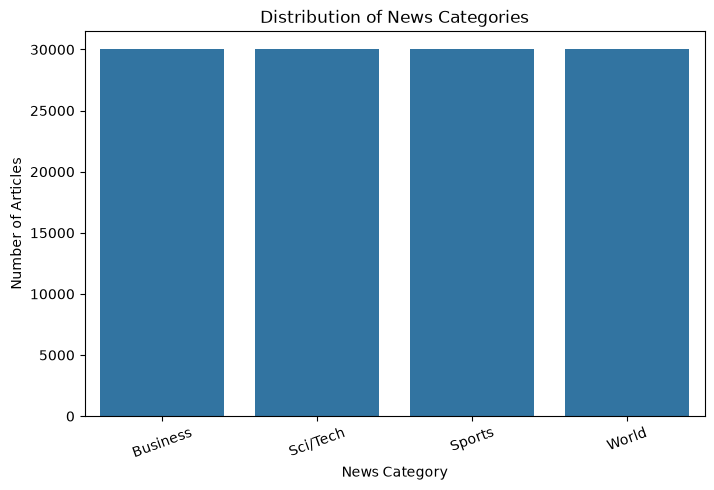

In [94]:
plt.figure(figsize=(8, 5))

sns.countplot(data=train_df, x="category")

plt.title("Distribution of News Categories")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=20)

In [96]:
train_df["word_count"] = train_df["text"].apply(
    lambda x: len(x.split())
)

print(train_df["word_count"].describe())

count    120000.000000
mean         37.847450
std          10.085245
min           8.000000
25%          32.000000
50%          37.000000
75%          43.000000
max         177.000000
Name: word_count, dtype: float64


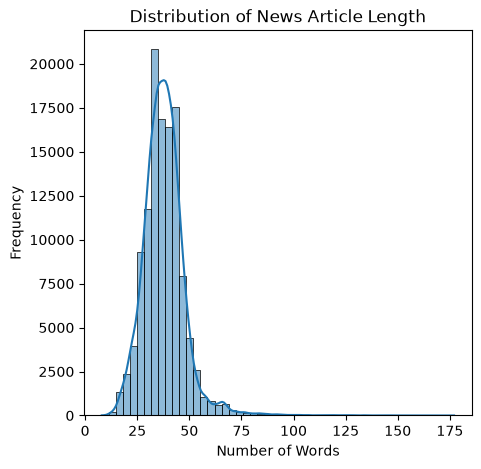

In [98]:
plt.figure(figsize=(5, 5))

sns.histplot(data=train_df, x="word_count", bins=50, kde=True)

plt.title("Distribution of News Article Length")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

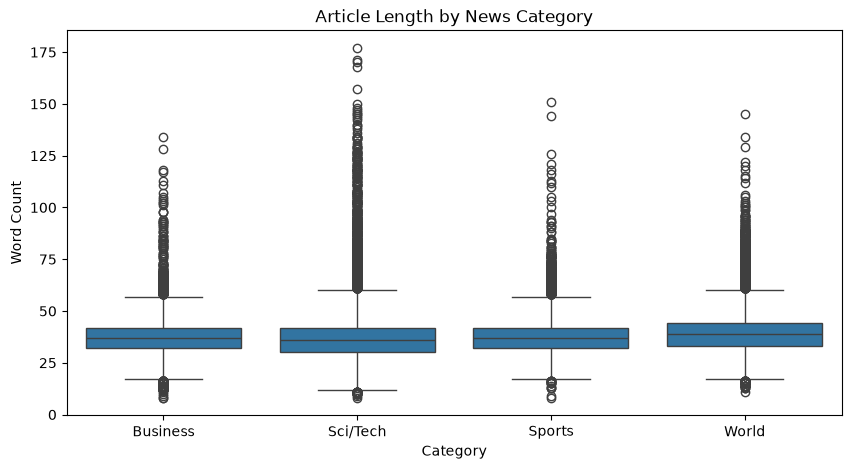

In [99]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=train_df, x="category", y="word_count")

plt.title("Article Length by News Category")
plt.xlabel("Category")
plt.ylabel("Word Count")

plt.show()

In [100]:
from collections import Counter
import re

all_text = " ".join(train_df["text"].astype(str))

words = re.findall(r'\b[a-zA-Z]+\b', all_text.lower())

word_freq = Counter(words)

print(word_freq.most_common(20))

[('the', 205478), ('to', 120746), ('a', 113353), ('of', 98652), ('in', 96425), ('and', 69678), ('s', 61984), ('on', 57667), ('for', 50674), ('that', 28169), ('with', 26812), ('as', 25378), ('at', 25068), ('its', 22123), ('is', 22098), ('new', 21427), ('by', 20942), ('it', 20538), ('said', 20267), ('reuters', 19340)]


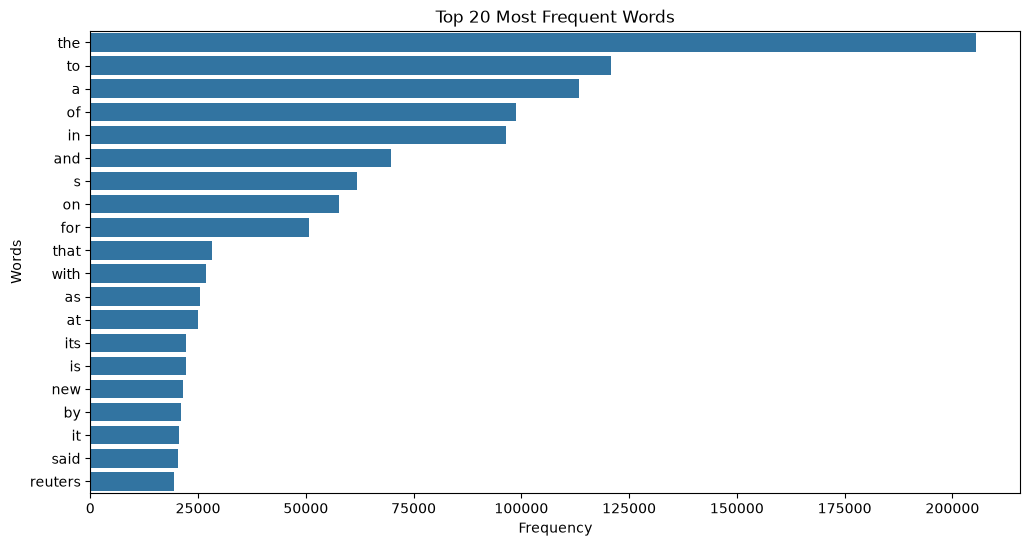

In [101]:
top_words = word_freq.most_common(20)

words, counts = zip(*top_words)

plt.figure(figsize=(12, 6))

sns.barplot(x=list(counts), y=list(words))

plt.title("Top 20 Most Frequent Words")
plt.xlabel("Frequency")
plt.ylabel("Words")

plt.show()